# Von Mises navigation policy

Navigating animals must consistently orient in a meaningful direction to reach
specific goals. The normative account behind this notebook (the paper's feature
box, *The von Mises distribution as a model of navigation behavior*) gives the
von Mises policy in two steps.

**Utility and its gradient.** The utility of navigational behavior is the
negated distance to a goal,

$$
U(\mathbf{x}, \mathbf{g}) \;=\; -\,\kappa\,\lVert\mathbf{x}-\mathbf{g}\rVert,
$$

with $\lVert\mathbf{x}-\mathbf{g}\rVert$ the Euclidean distance and
$\kappa$ a precision (inverse scale) parameter. Maximizing utility means
moving along the gradient

$$
\nabla_{\mathbf{x}} U(\mathbf{x},\mathbf{g})
\;=\; \kappa\,\frac{\mathbf{g}-\mathbf{x}}{\lVert\mathbf{g}-\mathbf{x}\rVert}
\;=\; \kappa\,\mathbf{u}(\mathbf{x}),
$$

where $\mathbf{u}(\mathbf{x}) = (u_1, u_2)$ is the unit vector pointing from
the current position $\mathbf{x}$ toward the target $\mathbf{g}$ and
$\nabla_{\mathbf{x}} = [\partial/\partial x_1,\, \partial/\partial x_2]$.
The angle of this unit vector (in radians) is the **goal heading**,

$$
\mu(\mathbf{x}) \;=\; \operatorname{atan2}\bigl(u_2(\mathbf{x}),\,
u_1(\mathbf{x})\bigr).
$$

**The heading policy.** Motion is a sequence of discrete, constant-length
steps,

$$
\mathbf{x}(t+1) = \mathbf{x}(t) + \delta\mathbf{x}_t,
\qquad
y_t = \operatorname{atan2}(\delta x_{t,2},\, \delta x_{t,1}),
$$

where $y_t$ is the heading of step $t$. With no goal information the heading
policy is uniform, $q(y) = 1/(2\pi)$ (equivalently
$y \sim \mathcal{U}(-\pi, \pi]$), a constant-step random walk. To
maximize navigational utility, the animal reweights this uniform prior by
each heading's alignment with the utility gradient:

$$
p(y \mid \mathbf{x})
\;\propto\; q(y)\,\exp\!\big(\kappa\,
\mathbf{u}(\mathbf{x})^{\top} \delta\mathbf{x}\big)
\;=\; \frac{1}{2\pi}\,
\exp\!\big(\kappa \cos(y - \mu(\mathbf{x}))\big),
$$

which is exactly the **von Mises distribution** (up to the normalizing
constant $Z(\kappa)$). It is the optimal, utility-maximizing policy under
discrete steps of constant size in the absence of other constraints:
$\mu(\mathbf{x})$ is the goal direction the animal aims at, and $\kappa$
sets how strongly the step concentrates toward it.

The figure shows this policy for each $\kappa \in \{0, 0.5, 2, 5\}$. The
**top row** displays the von Mises density $p(y \mid \mathbf{x})$ centered
on the position-dependent goal heading $\mu(\mathbf{x})$, rendered as a
radial modulation around the policy radius with the goal direction marked.
The **bottom row** shows 10 trajectories sampled from the same policies, from
the starting position $\mathbf{x}(t{=}0)$ (circle) toward the target
$\mathbf{g}$ (triangle).

This is a *policy* illustration: it characterizes the stochastic heading
distribution that goal-directed control expresses. It is the visual companion
to the *likelihood* use of the von Mises distribution in
`notebooks_r/beetles.ipynb` and `notebooks_r/zebra_escape.ipynb`, where fits
to observed headings directly estimate such behavioral policies, with $\mu$
the intended direction and $\kappa$ the strength of directional control.


## Setup

Select the R (`ir`) kernel and follow the [R setup](../getting-started-r.md)
page for the environment and kernel prerequisites; the first code cell
checks the pinned packages and stops with a pointer there if the
one-time setup has not been run. Run the cells in order.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("circular", "ggplot2", "ragg", "IRdisplay", "patchwork")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c("circular", "ggplot2", "ragg", "IRdisplay", "patchwork"),
    function(p) as.character(packageVersion(p)), character(1)))
versions


R  circular   ggplot2      ragg IRdisplay patchwork 
  "4.5.3"   "0.5.2"   "4.0.3"   "1.5.2"     "1.1"   "1.3.2"

In [3]:
suppressPackageStartupMessages({
  library(circular)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}


In [5]:
FIG_DIR <- file.path(repo_root, "figures", "von_mises_policy")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
# Render PNGs for inline display; keep vector PDFs alongside them.

show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}

theme_set(theme_minimal(base_size = 12))
save_figure <- function(plot, name, width = 8, height = 5) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot, width = width, height = height)
  show_figure(plot, name, width, height)
}


In [6]:
SEED <- 12345
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- if (quick_run) 2L else 4L
ITER <- if (quick_run) 3000L else 4000L
WARMUP <- if (quick_run) 1500L else 2000L
# These are local execution budgets, not convergence claims. Hard diagnostic
# gates below apply to both budgets; increase sampling if they fail.


In [7]:
wrap <- function(x) atan2(sin(x), cos(x))
circ_mean <- function(x) atan2(mean(sin(x)), mean(cos(x)))
resultant <- function(x) Mod(mean(exp(1i * x)))
softplus_stable <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
log1p_exp <- softplus_stable
A1_safe <- function(k) {
  z <- besselI(k, 1, expon.scaled = TRUE) / besselI(k, 0, expon.scaled = TRUE)
  if (!is.null(dim(k))) dim(z) <- dim(k)
  z
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) - log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  ii <- seq_len(length(x) - gap)
  j <- ii[which.min(x[ii + gap] - x[ii])]
  c(low = x[j], high = x[j + gap])
}
interval <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  z <- if (angular) m + wrap(x - m) else x
  c(mean = m, hdi(z, prob))
}
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
draw_vm <- function(mu, kappa) {
  wrap(as.numeric(circular::rvonmises(1, mu = vmu(mu), kappa = kappa,
                                     control.circular = vm_ctrl)))
}


## Figure style

Figures use the shared minimal theme. Each figure renders inline and saves a vector PDF under `figures/von_mises_policy/`.


## 1. The heading policy and its configuration

`goal_heading(x, g)` implements the goal heading
$\mu(\mathbf{x}) = \operatorname{atan2}(u_2(\mathbf{x}),
u_1(\mathbf{x}))$ from the unit vector
$\mathbf{u}(\mathbf{x}) =
(\mathbf{g}-\mathbf{x})/\lVert\mathbf{g}-\mathbf{x}\rVert$.
`vm_logpdf` and `vonmises_pdf` give the exact density
$p(y \mid \mu, \kappa) = Z(\kappa)^{-1}
e^{\kappa \cos(y-\mu)}$ (in log form via $I_0$), and `draw_vm` samples
headings $y \sim p(\cdot \mid \mu, \kappa)$. The configuration fixes the
starting position $\mathbf{x}(t{=}0) = (0, 0)$, the target
$\mathbf{g} = (0, 10)$, the concentrations
$\kappa \in \{0, 0.5, 2, 5\}$, the constant step length
$\lVert \delta\mathbf{x} \rVert = 0.15$ over $T = 300$ steps, and the
(per-column) sampling seeds, so the panels differ only in $\kappa$.


In [8]:
goal_heading <- function(x, y) atan2(y[2] - x[2], y[1] - x[1])
vonmises_pdf <- function(theta, mu, kappa) exp(vm_logpdf(theta, mu, kappa))
x_start <- c(0.0, 0.0)
target <- c(0.0, 10.0)
kappas <- c(0, 0.5, 2, 5)
T_steps <- 300L
step_len <- 0.15
num_traj <- 10L
rng_seed <- 12345L
R_policy <- 1.75
amp <- 1.0
# Keep all geometry and trajectory counts fixed even in quick mode.
# EQUIVALENCE NOTE: circular exports rvonmises, not rmv. The scalar
# rvonmises call uses the tutorial's warning-free control.circular pattern.


## 2. Evaluate the policy and sample trajectories

The top row evaluates the exact density $p(y \mid \mathbf{x})$ on a fine
angle grid $y \in [0, 2\pi)$ for each $\kappa$ and renders it as a radial
modulation around the policy radius, with the goal heading
$\mu(\mathbf{x}(t{=}0))$ marked. The bottom row applies the same policy over
time: at every step of every trajectory a heading is drawn from
$p(y_t \mid \mathbf{x}(t))$ and the position updates by
$\delta\mathbf{x}_t = \lVert\delta\mathbf{x}\rVert (\cos y_t,
\sin y_t)$. The two rows are the same policy seen two ways; their agreement
is the point of the figure.


In [9]:
theta_grid <- (0:1023) * (2 * pi / 1024)
mu0 <- goal_heading(x_start, target)
radials <- lapply(kappas, function(kappa) {
  pdf <- vonmises_pdf(theta_grid, mu0, kappa)
  R_policy + amp * (pdf - min(pdf)) / (max(pdf) - min(pdf) + 1e-12)
})
trajectories <- vector("list", length(kappas))
for (i in seq_along(kappas)) {
  set.seed(rng_seed + i - 1L)
  pos <- array(0, dim = c(T_steps + 1L, num_traj, 2L))
  for (j in seq_len(num_traj)) pos[1, j, ] <- x_start
  for (t in seq_len(T_steps)) {
    for (j in seq_len(num_traj)) {
      mu <- goal_heading(pos[t, j, ], target)
      theta <- draw_vm(mu, kappas[i])
      pos[t + 1L, j, ] <- pos[t, j, ] + step_len * c(cos(theta), sin(theta))
    }
  }
  steps <- sqrt(diff(pos[, 1, 1])^2 + diff(pos[, 1, 2])^2)
  stopifnot(all(abs(steps - step_len) < 1e-10))
  trajectories[[i]] <- pos
}
# R and NumPy use different von Mises random-number implementations and
# precision (R doubles versus Python float32); paths have distributional,
# not bitwise, parity. Geometry, seeds, counts, and step lengths match.


## 3. Draw the figure

The following cells compose the two-row figure and save it as a vector PDF
under `figures/von_mises_policy/`; the PNG is rendered inline.


In [10]:
policy_panels <- trajectory_panels <- vector("list", length(kappas))
# Policy panels follow the Python twin (von_mises_policy_plots.py,
# plot_navigation): the density curve is embedded in the policy plane as
# x_start + radius * cos/sin(theta) - the same plane as the trajectory
# panels below - with the policy circle (radius R_policy around the
# start), a dot at the start and the goal-direction marker drawn
# directly, instead of a separate polar panel.
Rmax_policy <- R_policy + amp
ref_ring <- data.frame(
  x = x_start[1] + R_policy * cos(seq(0, 2 * pi, length.out = 361L)),
  y = x_start[2] + R_policy * sin(seq(0, 2 * pi, length.out = 361L)))
for (i in seq_along(kappas)) {
  polar <- data.frame(x = x_start[1] + radials[[i]] * cos(theta_grid),
    y = x_start[2] + radials[[i]] * sin(theta_grid))
  policy_panels[[i]] <- ggplot(polar, aes(x, y)) +
    geom_path(aes(group = 1), colour = "black", linewidth = 0.6) +
    geom_path(data = ref_ring, inherit.aes = FALSE, aes(x, y),
      colour = "black", alpha = 0.95, linewidth = 0.3) +
    annotate("point", x = x_start[1], y = x_start[2], colour = "black", size = 2) +
    annotate("point",
      x = x_start[1] + (R_policy + amp + 0.22) * cos(mu0),
      y = x_start[2] + (R_policy + amp + 0.22) * sin(mu0),
      colour = "black", shape = 17, size = 2.5) +
    scale_x_continuous(limits = x_start[1] + c(-1, 1) * (Rmax_policy + 0.3),
      expand = c(0, 0)) +
    scale_y_continuous(limits = x_start[2] + c(-1, 1) * (Rmax_policy + 0.3),
      expand = c(0, 0)) +
    coord_equal() +
    labs(title = paste("kappa =", kappas[i]), x = "", y = "Policy density") +
    theme_void(base_size = 12)
  pos <- trajectories[[i]]
  seg <- do.call(rbind, lapply(seq_len(num_traj), function(j) {
    data.frame(iteration = seq_len(T_steps), trajectory = factor(j),
      x = pos[-(T_steps + 1L), j, 1], y = pos[-(T_steps + 1L), j, 2],
      xend = pos[-1L, j, 1], yend = pos[-1L, j, 2])
  }))
  # Segments encode consecutive time points explicitly: no sorting of an
  # x/y path can change a trajectory's temporal order.
  trajectory_panels[[i]] <- ggplot(seg, aes(x, y, colour = trajectory)) +
    geom_segment(aes(xend = xend, yend = yend), linewidth = 0.3, alpha = 0.9) +
    annotate("point", x = x_start[1], y = x_start[2], colour = "black", size = 2) +
    annotate("point", x = target[1], y = target[2], colour = "black", shape = 17, size = 2.5) +
    scale_colour_manual(values = c("#1F77B4", "#FF7F0E", "#2CA02C", "#D62728", "#9467BD",
      "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22", "#17BECF")) +
    coord_equal(xlim = c(-7.5, 7.5), ylim = c(-3.5, 10.8)) +
    theme_void(base_size = 12) + theme(legend.position = "none")
}


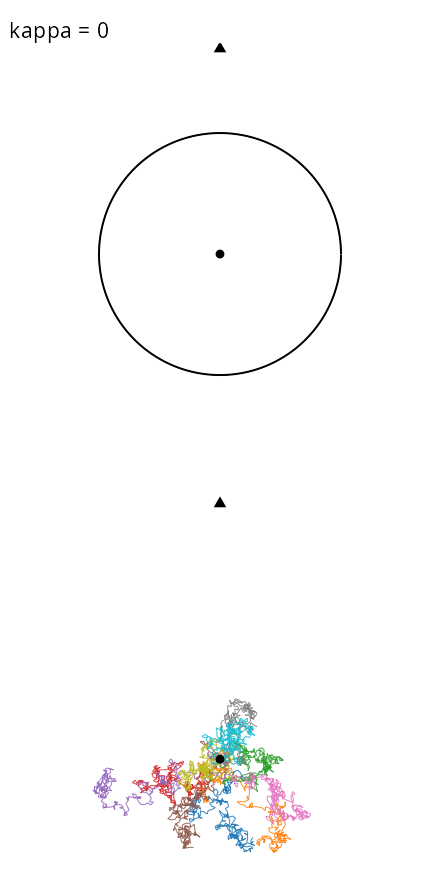

In [11]:
column_1 <- patchwork::wrap_plots(policy_panels[[1]], trajectory_panels[[1]], ncol = 1)
save_figure(column_1, "vonmises_navigation_kappa_0", 4, 8)


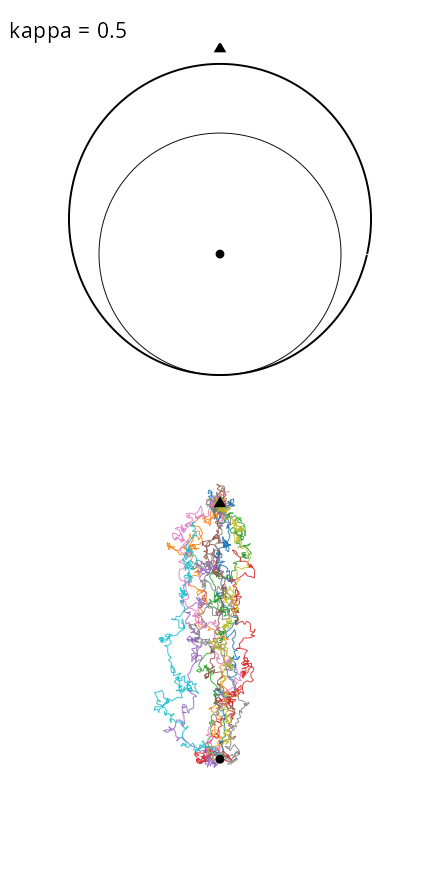

In [12]:
column_2 <- patchwork::wrap_plots(policy_panels[[2]], trajectory_panels[[2]], ncol = 1)
save_figure(column_2, "vonmises_navigation_kappa_0_5", 4, 8)


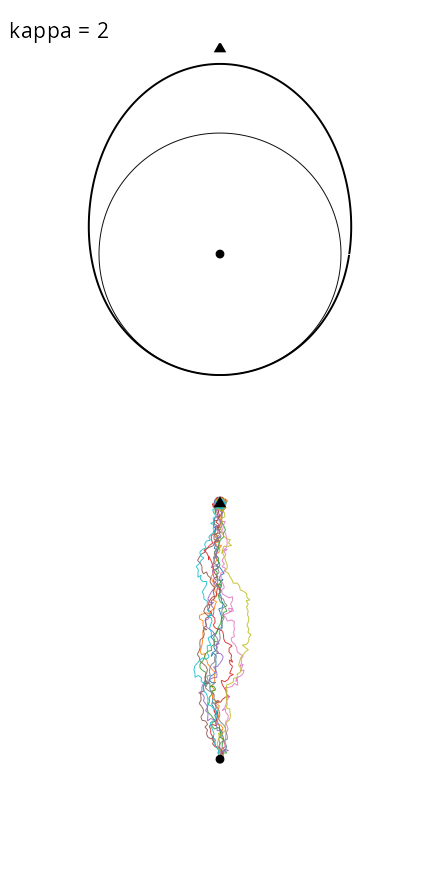

In [13]:
column_3 <- patchwork::wrap_plots(policy_panels[[3]], trajectory_panels[[3]], ncol = 1)
save_figure(column_3, "vonmises_navigation_kappa_2", 4, 8)


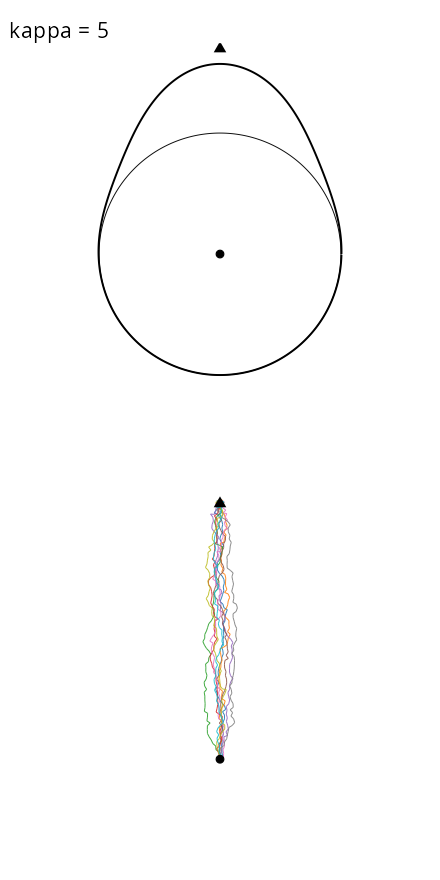

In [14]:
column_4 <- patchwork::wrap_plots(policy_panels[[4]], trajectory_panels[[4]], ncol = 1)
save_figure(column_4, "vonmises_navigation_kappa_5", 4, 8)


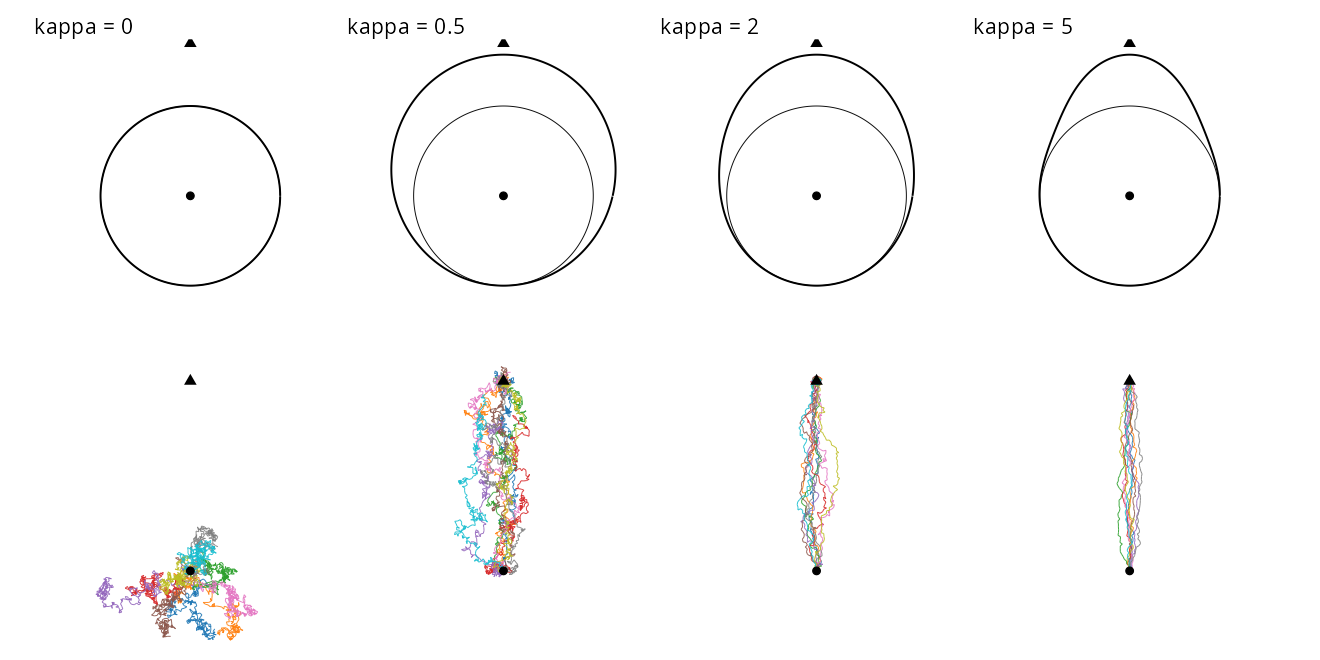

In [15]:
p_navigation <- patchwork::wrap_plots(c(policy_panels, trajectory_panels), ncol = length(kappas))
save_figure(p_navigation, "vonmises_navigation", 12, 6)


## How to read the panels

- **$\kappa = 0$**: the policy reduces to the uniform prior
  $q(y) = 1/(2\pi)$, the top-row curve is a circle, and the trajectories are
  constant-step random walks — no net progress toward $\mathbf{g}$ on
  average.
- **$\kappa = 0.5 / 2 / 5$**: the density sharpens into a lobe around the
  goal heading $\mu(\mathbf{x})$ and the trajectories progressively align
  with the utility gradient $\nabla_{\mathbf{x}} U$; by $\kappa = 5$ the
  walk makes steady, low-deviation progress toward $\mathbf{g}$.
- The fixed step length, $T$, and starting position keep the panels directly
  comparable, isolating the single effect of the concentration $\kappa$.

The two rows are the same object: the top row is the policy density
$p(y \mid \mathbf{x})$, the bottom row is that policy applied step by step
over time. Agreement between them is the point.
